# Exploratory Data Analysis – Medical Insurance Charges

## Project purpose
This notebook explores the prepared medical insurance dataset before modeling. It previews the records, studies how BMI and smoking status relate to charges, and examines correlations among numeric columns.

**Generative AI contribution:** AI assistance supported learning the plotting functions, interpreting code, troubleshooting, and documenting the analysis. The charts and conclusions should be validated against the actual data.

> EDA describes patterns in this dataset. A relationship or correlation does not, by itself, prove causation.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load the prepared dataset

Load the cleaned CSV created during data wrangling. Confirm that the filename and working directory are correct before running this cell.

In [19]:
df = pd.read_csv("updated_medical_insurance_dataset.csv")

## 2. Preview the records

`head(10)` displays the first ten rows. This is a quick check of column names, values, and whether the data appears to have loaded correctly.

In [20]:
print(df.head(10))

    age  gender     bmi  no_of_children  smoker  region      charges
0  19.0       1  27.900               0       1       3  16884.92400
1  18.0       2  33.770               1       0       4   1725.55230
2  28.0       2  33.000               3       0       4   4449.46200
3  33.0       2  22.705               0       0       1  21984.47061
4  32.0       2  28.880               0       0       1   3866.85520
5  31.0       1  25.740               0       0       4   3756.62160
6  46.0       1  33.440               1       0       4   8240.58960
7  37.0       1  27.740               3       0       1   7281.50560
8  37.0       2  29.830               2       0       2   6406.41070
9  60.0       1  25.840               0       0       1  28923.13692


## 3. Explore BMI versus insurance charges

A regression plot displays the observed BMI and charge values and overlays a fitted trend line. Use it to inspect the direction and general shape of the association; it does not establish that BMI causes the charges.

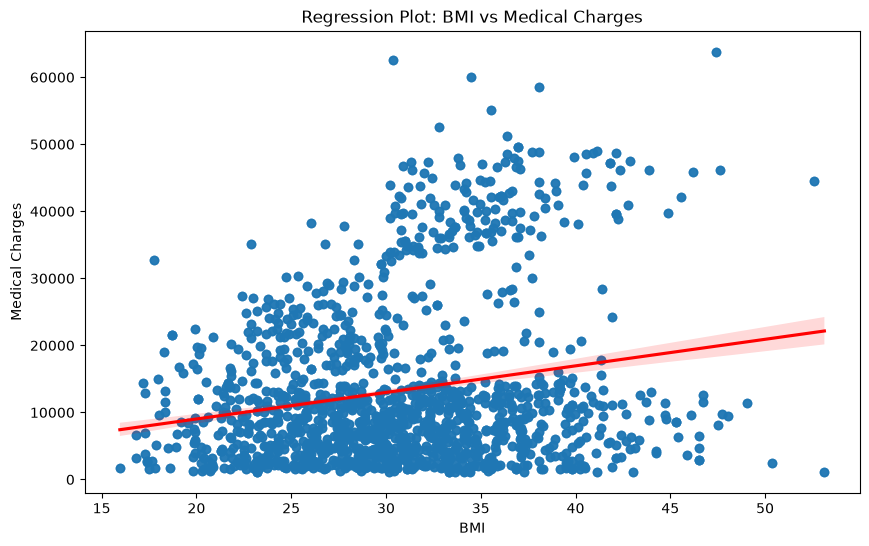

<Figure size 640x480 with 0 Axes>

In [23]:
plt.figure(figsize=(10, 6))

sns.regplot(
    x='bmi',
    y='charges',
    data=df,
    line_kws={'color': 'red'}
)

plt.title('Regression Plot: BMI vs Medical Charges')
plt.xlabel('BMI')
plt.ylabel('Medical Charges')

plt.show()
plt.tight_layout()
plt.savefig("C:/Users/sauno/OneDrive/Documents/project/reports/regression_plot_BMI_vs_Medical_Charges.png")
plt.show()

## 4. Compare charges by smoking status

A box plot compares the distribution of insurance charges for the smoking categories. The median, spread, and potential outliers can be compared between groups.

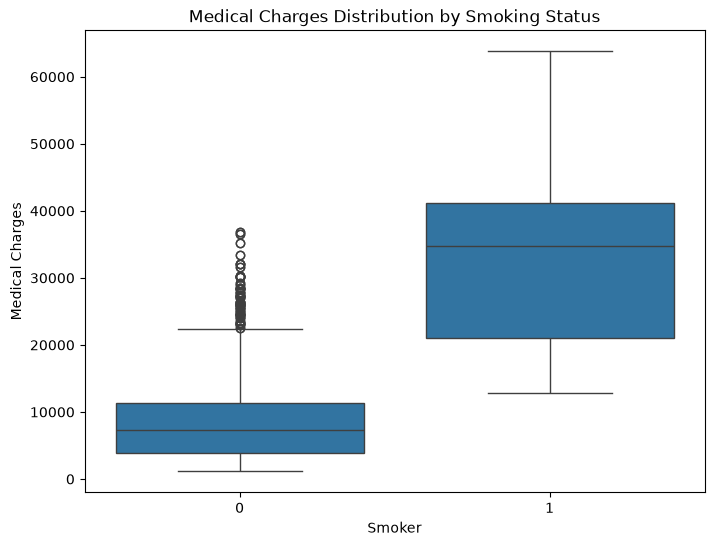

<Figure size 640x480 with 0 Axes>

In [26]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    x='smoker',
    y='charges',
    data=df
)

plt.title('Medical Charges Distribution by Smoking Status')
plt.xlabel('Smoker')
plt.ylabel('Medical Charges')

plt.show()
plt.tight_layout()
plt.savefig("C:/Users/sauno/OneDrive/Documents/project/reports/boxplot_smoker_vs_charges.png")
plt.show()

## 5. Calculate numeric correlations

The correlation matrix calculates pairwise correlations for numeric columns only. Correlation values range from -1 to +1 and describe linear association.

In [28]:
# Calculate correlation matrix
correlation_matrix = df.corr(numeric_only=True)

# Print correlation matrix
print(correlation_matrix)

                     age    gender       bmi  no_of_children    smoker  \
age             1.000000 -0.026059  0.113068        0.037631 -0.023305   
gender         -0.026059  1.000000  0.042924        0.016020  0.082326   
bmi             0.113068  0.042924  1.000000       -0.001492  0.011489   
no_of_children  0.037631  0.016020 -0.001492        1.000000  0.006362   
smoker         -0.023305  0.082326  0.011489        0.006362  1.000000   
region         -0.007180  0.022213  0.271119       -0.025717  0.054077   
charges         0.298694  0.062837  0.199846        0.066442  0.788783   

                  region   charges  
age            -0.007180  0.298694  
gender          0.022213  0.062837  
bmi             0.271119  0.199846  
no_of_children -0.025717  0.066442  
smoker          0.054077  0.788783  
region          1.000000  0.054058  
charges         0.054058  1.000000  


## 6. Visualize the correlation matrix

The heatmap makes the numeric correlation matrix easier to scan. Stronger positive and negative correlations appear with more intense colors according to the selected color map.

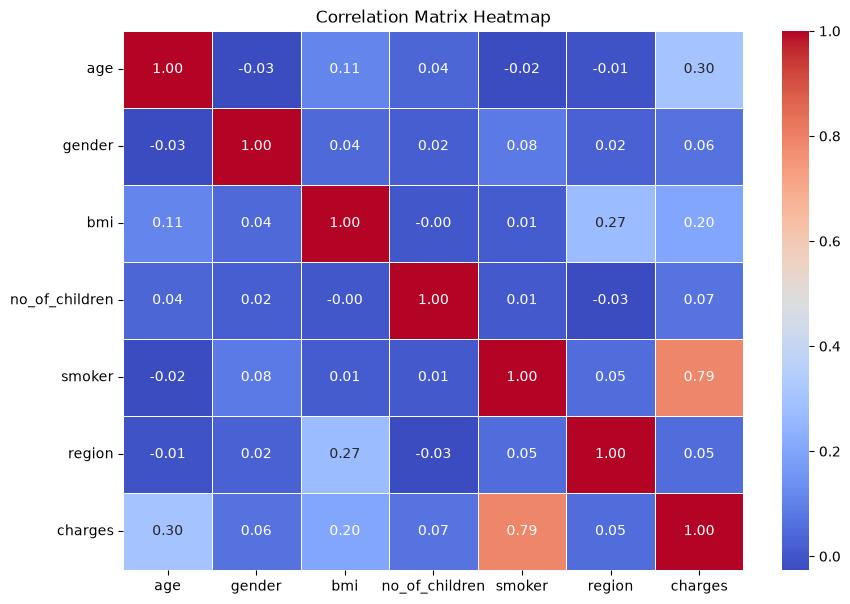

<Figure size 640x480 with 0 Axes>

In [30]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix Heatmap')
plt.show()
plt.tight_layout()
plt.savefig("C:/Users/sauno/OneDrive/Documents/project/reports/correlation_matrix.png")
plt.show()